In [1]:
from pathlib import Path
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from scipy.sparse import csr_matrix, hstack
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ----- Налаштування шляхів -----
INTERACTIONS_PATH = Path("filtered_interactions.parquet")
ITEMS_PATH = Path("filtered_items.parquet")
MODEL_PATH = Path("model_random_forest_opt.joblib")
TFIDF_PATH = Path("models/tfidf_vectorizer.joblib")
MLB_PATH = Path("models/multilabel_binarizer.joblib")
X_TRAIN_PATH = Path("data/training_splits/X_train.npz")
Y_TEST_PATH = Path("data/training_splits/y_test.npy")

# Параметри експерименту — тестові користувачі будуть однаковими для всіх K.
HISTORY_SIZES = [5, 10, 20, 50, 100]
SAMPLE_SIZE = 500_000         # як у user_profile.ipynb
TEST_SIZE = 0.20              # як у початковому train_test_split
RANDOM_STATE = 42
MAX_EVAL_USERS = 10_000       # None = усі доступні тестові користувачі
BATCH_SIZE = 5_000
OUTPUT_DIR = Path(
    "results/random_forest_history_experiment"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

required_paths = [INTERACTIONS_PATH, ITEMS_PATH, MODEL_PATH, TFIDF_PATH, MLB_PATH, X_TRAIN_PATH]
missing = [str(p) for p in required_paths if not p.exists()]
if missing:
    raise FileNotFoundError(
        "Не знайдено потрібні файли:\n- " + "\n- ".join(missing) +
        "\nПеревір шляхи у клітинці конфігурації."
    )

print("Конфігурацію завантажено.")
print("Каталог результатів:", OUTPUT_DIR.resolve())

Конфігурацію завантажено.
Каталог результатів: D:\Progect\Practic2026\Models\results\random_forest_history_experiment


## 1. Завантаження моделі та артефактів

Завантажуємо збережену модель, TF-IDF-векторизатор і `MultiLabelBinarizer`, який визначає точний порядок 42 жанрових ознак. Порядок ознак має відповідати порядку під час навчання.

In [2]:
model = joblib.load(MODEL_PATH)
tfidf = joblib.load(TFIDF_PATH)
mlb = joblib.load(MLB_PATH)

# У моделі X було сформовано в такому порядку:
# [42 ознаки профілю користувача] + [42 жанри цільового аніме] + [5000 TF-IDF]
genre_columns = list(mlb.classes_)
n_genres = len(genre_columns)
n_text_features = len(tfidf.get_feature_names_out())
expected_features = n_genres * 2 + n_text_features

print(f"Жанрових ознак: {n_genres}")
print(f"TF-IDF ознак: {n_text_features}")
print(f"Очікувана кількість ознак: {expected_features}")
print(f"Кількість ознак у моделі: {getattr(model, 'n_features_in_', 'невідомо')}")

if hasattr(model, "n_features_in_") and model.n_features_in_ != expected_features:
    raise ValueError(
        f"Модель очікує {model.n_features_in_} ознак, але завантажені артефакти дають "
        f"{expected_features}. Перевір, чи модель, TF-IDF та MultiLabelBinarizer походять "
        "з одного запуску пайплайна."
    )

Жанрових ознак: 42
TF-IDF ознак: 5000
Очікувана кількість ознак: 5084
Кількість ознак у моделі: 5084


## 2. Завантаження взаємодій та формування цільового тестового набору

Відтворюємо вибірку з 500 000 взаємодій і `train_test_split(test_size=0.2, random_state=42)`, як у `user_profile.ipynb`. Це дає змогу порівнювати K на одному й тому самому наборі цільових оцінок. У тест увійдуть лише аніме, для яких доступні жанрові та текстові ознаки.

In [3]:
interactions_all = pd.read_parquet(INTERACTIONS_PATH)
items_all = pd.read_parquet(ITEMS_PATH)

required_interaction_cols = {"user_id", "anime_id", "rating"}
required_item_cols = {"anime_id", "Genres"}
if not required_interaction_cols.issubset(interactions_all.columns):
    raise ValueError(f"У interactions мають бути колонки: {required_interaction_cols}")
if not required_item_cols.issubset(items_all.columns):
    raise ValueError(f"У items мають бути колонки: {required_item_cols}")

# Відтворюємо кроки user_profile.ipynb: залишаємо аніме, наявні в каталозі.
valid_item_ids = set(items_all["anime_id"].dropna().unique())
interactions = interactions_all.loc[
    interactions_all["anime_id"].isin(valid_item_ids),
    ["user_id", "anime_id", "rating"]
].copy()

# Ідентичний розмір і seed вибірки, що використовувалися в початковому ноутбуці.
if len(interactions) < SAMPLE_SIZE:
    raise ValueError(
        f"Після фільтрації залишилося {len(interactions):,} взаємодій, "
        f"але SAMPLE_SIZE={SAMPLE_SIZE:,}. Перевір, що завантажено правильний parquet."
    )

sampled = interactions.sample(n=SAMPLE_SIZE, random_state=RANDOM_STATE).copy()
sampled = sampled.reset_index(drop=True)
all_row_indices = np.arange(len(sampled))
_, test_indices = train_test_split(
    all_row_indices,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)
test_rows = sampled.iloc[test_indices].reset_index(drop=True)

print(f"Усі взаємодії після фільтрації: {len(interactions):,}")
print(f"Вибірка для відтворення експерименту: {len(sampled):,}")
print(f"Цільових тестових взаємодій до фільтрації користувачів: {len(test_rows):,}")

# Необов'язкова перевірка відповідності y_test, збереженому раніше.
if Y_TEST_PATH.exists():
    y_test_saved = np.load(Y_TEST_PATH)
    if len(y_test_saved) == len(test_rows) and np.allclose(
        y_test_saved, test_rows["rating"].to_numpy(), equal_nan=True
    ):
        print("Перевірка пройдена: відтворені тестові рейтинги збігаються з y_test.npy.")
    else:
        warnings.warn(
            "Відтворений порядок/вміст y_test не збігається з y_test.npy. "
            "Метрики нижче використовуватимуть цільові рейтинги із sampled. "
            "Перевір версію файлів і параметри попереднього розбиття."
        )

Усі взаємодії після фільтрації: 46,766,934
Вибірка для відтворення експерименту: 500,000
Цільових тестових взаємодій до фільтрації користувачів: 100,000
Перевірка пройдена: відтворені тестові рейтинги збігаються з y_test.npy.


## 3. Підготовка жанрових та текстових ознак аніме

Векторизатор не навчається повторно: використовуємо збережений TF-IDF, як і при навчанні Gradient Boosting. Важливо зберегти той самий порядок аніме та жанрів.

In [4]:
# Фільтрація і порядок items мають повторювати user_profile.ipynb.
items = items_all.loc[items_all["anime_id"].isin(interactions["anime_id"].unique())].copy()
items = items.reset_index(drop=True)

if "sypnopsis" in items.columns:
    synopsis_col = "sypnopsis"  # саме так колонка названа в user_profile.ipynb
elif "synopsis" in items.columns:
    synopsis_col = "synopsis"
else:
    raise ValueError("У items не знайдено колонку 'sypnopsis' або 'synopsis'.")

# Жанрова матриця — у порядку classes_ з навченого MultiLabelBinarizer.
genre_lists = (
    items["Genres"].fillna("").astype(str)
    .apply(lambda value: [g.strip() for g in value.split(",") if g.strip()])
)
genre_dense = mlb.transform(genre_lists)
G = csr_matrix(genre_dense.astype(np.float32))

# Перетворення описів навченим векторизатором (не fit_transform).
text_values = items[synopsis_col].fillna("").astype(str)
T = tfidf.transform(text_values).tocsr().astype(np.float32)

item_ids = items["anime_id"].to_numpy()
anime_to_idx = pd.Series(np.arange(len(item_ids), dtype=np.int32), index=item_ids)

print("Матриця жанрів:", G.shape)
print("Матриця TF-IDF:", T.shape)

if G.shape[1] != n_genres:
    raise ValueError("Кількість жанрових ознак не відповідає збереженому MultiLabelBinarizer.")
if T.shape[1] != n_text_features:
    raise ValueError("Кількість TF-IDF ознак не відповідає збереженому векторизатору.")
if test_rows["anime_id"].map(anime_to_idx).isna().any():
    raise ValueError("У тесті є anime_id, якого немає у сформованому каталозі items.")

Матриця жанрів: (7189, 42)
Матриця TF-IDF: (7189, 5000)


## 4. Вибір спільної когорти тестових користувачів

Щоб порівняння було коректним, кожен K оцінюється на **тих самих користувачах і тих самих цільових рейтингах**. Вибираємо користувачів, для яких після вилучення тестових пар доступно щонайменше 100 історичних оцінок. Для керованого часу виконання за замовчуванням беремо до 10 000 тестових користувачів; змінити це можна в конфігураційній клітинці.

In [5]:
# Випадково, але відтворювано обираємо користувачів з тестового набору.
unique_test_users = pd.Index(test_rows["user_id"].drop_duplicates())
rng = np.random.default_rng(RANDOM_STATE)
if MAX_EVAL_USERS is not None and len(unique_test_users) > MAX_EVAL_USERS:
    selected_user_ids = pd.Index(
        rng.choice(unique_test_users.to_numpy(), size=MAX_EVAL_USERS, replace=False)
    )
else:
    selected_user_ids = unique_test_users

# Обмежуємо обсяг завантаженої історії лише обраними користувачами.
history = interactions.loc[
    interactions["user_id"].isin(selected_user_ids),
    ["user_id", "anime_id", "rating"]
].copy()

# Усі тестові user-item пари виключаємо з історії, щоб рейтинги-мішені
# не потрапили до профілю ані на етапі K=5, ані при K=100.
test_pairs = test_rows.loc[
    test_rows["user_id"].isin(selected_user_ids), ["user_id", "anime_id"]
].drop_duplicates()
test_pair_index = pd.MultiIndex.from_frame(test_pairs)
history_pair_index = pd.MultiIndex.from_frame(history[["user_id", "anime_id"]])
history = history.loc[~history_pair_index.isin(test_pair_index)].copy()

# Стабільне псевдовипадкове впорядкування історії для кожного користувача.
# Через це історії вкладені: перші 5 оцінок входять до перших 10, і т.д.
history["_order"] = pd.util.hash_pandas_object(
    history[["user_id", "anime_id"]], index=False
).to_numpy(dtype=np.uint64)
history = history.sort_values(["user_id", "_order"], kind="mergesort")
history["_history_rank"] = history.groupby("user_id", sort=False).cumcount()

history_counts = history.groupby("user_id").size()
eligible_users = pd.Index(history_counts[history_counts >= max(HISTORY_SIZES)].index)

test_rows = test_rows.loc[test_rows["user_id"].isin(eligible_users)].reset_index(drop=True)
history = history.loc[
    history["user_id"].isin(eligible_users) &
    (history["_history_rank"] < max(HISTORY_SIZES))
].copy()

user_ids = pd.Index(sorted(test_rows["user_id"].unique()))
user_to_idx = pd.Series(np.arange(len(user_ids), dtype=np.int32), index=user_ids)
history["_user_idx"] = history["user_id"].map(user_to_idx).astype(np.int32)
history["_item_idx"] = history["anime_id"].map(anime_to_idx)

if history["_item_idx"].isna().any():
    raise ValueError("У історії знайдено anime_id без жанрових ознак.")
history["_item_idx"] = history["_item_idx"].astype(np.int32)

test_rows["_user_idx"] = test_rows["user_id"].map(user_to_idx).astype(np.int32)
test_rows["_item_idx"] = test_rows["anime_id"].map(anime_to_idx).astype(np.int32)

y_true = test_rows["rating"].to_numpy(dtype=np.float32)
print(f"Користувачів у спільній когорті: {len(user_ids):,}")
print(f"Тестових прогнозів на кожне K: {len(test_rows):,}")
print(f"Мінімальна кількість історичних оцінок: {history.groupby('user_id').size().min():,}")

if test_rows.empty:
    raise ValueError(
        "Не залишилося тестових користувачів із 100 історичними оцінками. "
        "Перевір дані або зменш HISTORY_SIZES/MAX_EVAL_USERS."
    )

Користувачів у спільній когорті: 8,234
Тестових прогнозів на кожне K: 12,019
Мінімальна кількість історичних оцінок: 100


## 5. Значення для заповнення жанрів, відсутніх у короткій історії

Якщо користувач не оцінював аніме певного жанру, його профіль не має середньої оцінки цього жанру. Під час початкової підготовки пропуски заповнювалися середнім значенням ознаки. Тут використовуємо середні значення перших 42 ознак із `X_train.npz`, тобто лише тренувальної матриці.

In [6]:
X_train_saved = sparse.load_npz(X_TRAIN_PATH)
if X_train_saved.shape[1] != expected_features:
    raise ValueError(
        f"X_train має {X_train_saved.shape[1]} ознак, очікувалося {expected_features}."
    )

# Середнє кожної користувацької жанрової ознаки.
user_genre_fill_values = np.asarray(
    X_train_saved[:, :n_genres].mean(axis=0)
).ravel().astype(np.float32)

print("Підготовлено значення для заповнення відсутніх жанрових уподобань.")

Підготовлено значення для заповнення відсутніх жанрових уподобань.


## 6. Функції для формування профілю K та прогнозування

Кожна модель prediction виконується на ознаках тієї самої структури, що й під час навчання: жанровий профіль користувача + жанри цільового аніме + TF-IDF опису. Модель не навчається повторно.

In [7]:
def build_user_profiles(k: int) -> np.ndarray:
    """Повертає профіль [кількість користувачів, кількість жанрів] для заданого K."""
    h = history.loc[history["_history_rank"] < k]

    R_k = csr_matrix(
        (
            h["rating"].to_numpy(dtype=np.float32),
            (
                h["_user_idx"].to_numpy(dtype=np.int32),
                h["_item_idx"].to_numpy(dtype=np.int32),
            ),
        ),
        shape=(len(user_ids), len(item_ids)),
        dtype=np.float32,
    )

    # Сума рейтингів за жанром та кількість історичних тайтлів цього жанру.
    rating_sums = (R_k @ G).toarray()
    rating_counts = ((R_k != 0).astype(np.float32) @ G).toarray()

    profiles = np.divide(
        rating_sums,
        rating_counts,
        out=np.full_like(rating_sums, np.nan, dtype=np.float32),
        where=rating_counts != 0,
    )

    # Повторюємо схему заповнення пропусків, використану під час підготовки X.
    missing = ~np.isfinite(profiles)
    if missing.any():
        profiles[missing] = np.broadcast_to(user_genre_fill_values, profiles.shape)[missing]

    return profiles.astype(np.float32, copy=False)


def predict_in_batches(profiles: np.ndarray, batch_size: int = BATCH_SIZE) -> np.ndarray:
    """Будує ознаки тестових пар блоками й прогнозує завантаженою моделлю."""
    predictions = np.empty(len(test_rows), dtype=np.float32)
    target_user_idx = test_rows["_user_idx"].to_numpy(dtype=np.int32)
    target_item_idx = test_rows["_item_idx"].to_numpy(dtype=np.int32)

    for start in range(0, len(test_rows), batch_size):
        end = min(start + batch_size, len(test_rows))
        ix = slice(start, end)

        X_user = csr_matrix(profiles[target_user_idx[ix]], dtype=np.float32)
        X_item_genres = G[target_item_idx[ix]]
        X_item_text = T[target_item_idx[ix]]
        X_eval = hstack([X_user, X_item_genres, X_item_text], format="csr", dtype=np.float32)

        if X_eval.shape[1] != expected_features:
            raise ValueError(f"X_eval має {X_eval.shape[1]} ознак замість {expected_features}.")

        predictions[ix] = model.predict(X_eval).astype(np.float32)

    return predictions


def calculate_metrics(y: np.ndarray, y_hat: np.ndarray) -> dict:
    return {
        "MAE": mean_absolute_error(y, y_hat),
        "RMSE": np.sqrt(mean_squared_error(y, y_hat)),
        "R2": r2_score(y, y_hat),
        "n_predictions": len(y),
        "n_users": test_rows["user_id"].nunique(),
    }

print("Функції готові.")

Функції готові.


## 7. Запуск експериментів

Для кожного K формується інший профіль, але незмінними залишаються модель, тестові user-item пари, фактичні оцінки, жанри аніме та TF-IDF описи.

In [8]:
results = []
prediction_frames = []

for k in HISTORY_SIZES:
    print(f"\n===== K = {k} =====")
    profiles_k = build_user_profiles(k)
    y_pred = predict_in_batches(profiles_k)
    metrics = calculate_metrics(y_true, y_pred)
    metrics["history_size"] = k
    results.append(metrics)

    prediction_frames.append(pd.DataFrame({
        "history_size": k,
        "user_id": test_rows["user_id"].to_numpy(),
        "anime_id": test_rows["anime_id"].to_numpy(),
        "y_true": y_true,
        "y_pred": y_pred,
        "abs_error": np.abs(y_true - y_pred),
    }))

    print(
        f"MAE={metrics['MAE']:.4f} | "
        f"RMSE={metrics['RMSE']:.4f} | "
        f"R²={metrics['R2']:.4f} | "
        f"N={metrics['n_predictions']:,}"
    )

results_df = pd.DataFrame(results)[
    ["history_size", "MAE", "RMSE", "R2", "n_predictions", "n_users"]
].sort_values("history_size")

predictions_df = pd.concat(prediction_frames, ignore_index=True)

metrics_path = OUTPUT_DIR / "metrics_by_history_size.csv"
predictions_path = OUTPUT_DIR / "predictions_by_history_size.csv"
results_df.to_csv(metrics_path, index=False)
predictions_df.to_csv(predictions_path, index=False)

display(results_df)
print("\nМетрики збережено:", metrics_path)
print("Прогнози збережено:", predictions_path)


===== K = 5 =====
MAE=1.0725 | RMSE=1.4088 | R²=0.2867 | N=12,019

===== K = 10 =====
MAE=1.0397 | RMSE=1.3664 | R²=0.3290 | N=12,019

===== K = 20 =====
MAE=1.0091 | RMSE=1.3267 | R²=0.3674 | N=12,019

===== K = 50 =====
MAE=0.9845 | RMSE=1.2979 | R²=0.3946 | N=12,019

===== K = 100 =====
MAE=0.9692 | RMSE=1.2804 | R²=0.4108 | N=12,019


,history_size,MAE,RMSE,R2,n_predictions,n_users
0,5,1.072509,1.408823,0.286686,12019,8234
1,10,1.039682,1.366353,0.329045,12019,8234
2,20,1.009059,1.326687,0.367436,12019,8234
3,50,0.984472,1.297912,0.394577,12019,8234
4,100,0.969203,1.280431,0.410776,12019,8234



Метрики збережено: results\random_forest_history_experiment\metrics_by_history_size.csv
Прогнози збережено: results\random_forest_history_experiment\predictions_by_history_size.csv


## 8. Графіки порівняння

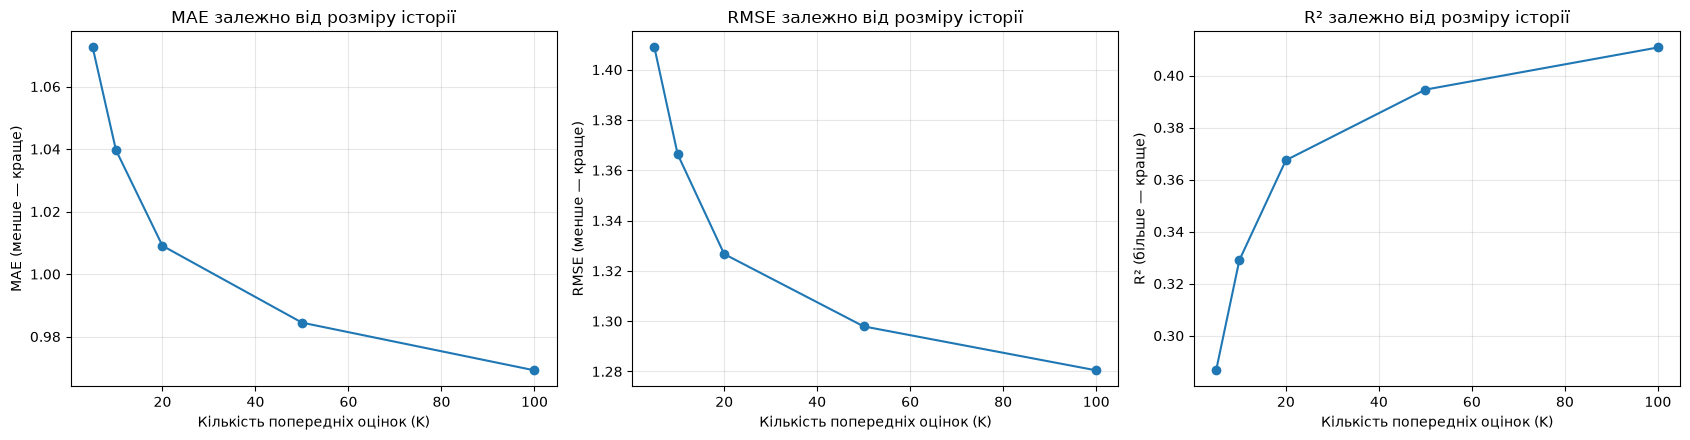

Графік збережено: results\random_forest_history_experiment\metrics_by_history_size.png


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].plot(results_df["history_size"], results_df["MAE"], marker="o")
axes[0].set_title("MAE залежно від розміру історії")
axes[0].set_xlabel("Кількість попередніх оцінок (K)")
axes[0].set_ylabel("MAE (менше — краще)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(results_df["history_size"], results_df["RMSE"], marker="o")
axes[1].set_title("RMSE залежно від розміру історії")
axes[1].set_xlabel("Кількість попередніх оцінок (K)")
axes[1].set_ylabel("RMSE (менше — краще)")
axes[1].grid(True, alpha=0.3)

axes[2].plot(results_df["history_size"], results_df["R2"], marker="o")
axes[2].set_title("R² залежно від розміру історії")
axes[2].set_xlabel("Кількість попередніх оцінок (K)")
axes[2].set_ylabel("R² (більше — краще)")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
figure_path = OUTPUT_DIR / "metrics_by_history_size.png"
plt.savefig(figure_path, dpi=160, bbox_inches="tight")
plt.show()
print("Графік збережено:", figure_path)

## 9. Як інтерпретувати результат

- Якщо MAE/RMSE зменшуються зі збільшенням K, довша історія допомагає моделі краще прогнозувати оцінки.
- Якщо покращення майже припиняється після певного K, додаткові оцінки дають невеликий приріст якості.
- Порівнювати слід значення з однієї таблиці: кількість користувачів і цільових тестових пар однакова для всіх K.

### Важливе обмеження

Цей ноутбук навмисно використовує готову модель без повторного навчання, як планується у системі. Проте в початковому `user_profile.ipynb` профілі для тренувальних прикладів були сформовані на основі повної таблиці взаємодій. Отже, модель могла опосередковано бачити рейтинги через профілі під час навчання. Тому це корисний експеримент поведінки **вже навченої** моделі при різному обсязі історії, але для строгої незалежної оцінки наукової якості потрібно окремо провести навчання без витоку тестових оцінок.